In [1]:
!pip install scikit-learn seaborn

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')

print("Все библиотеки загружены!")

Все библиотеки загружены!


In [3]:
df = pd.read_csv('winequality-red.csv', sep=';')

print(f"Размер датасета: {df.shape}")
print(f"Столбцы: {list(df.columns)}")
print()
print("Первые 5 строк:")
df.head()

Размер датасета: (1599, 12)
Столбцы: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Первые 5 строк:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


## Первичная информация о данных

- В датасете **1599 объектов** и **12 столбцов**: 11 признаков + целевая переменная `quality`.
- **Пропусков нет** — данные можно использовать без предварительной очистки.
- `quality` — целочисленный признак (оценка от 3 до 8), остальные признаки — вещественные.
- Типы данных корректные, дополнительное кодирование не требуется.

In [5]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


## Статистики по признакам

- В датасете 1599 объектов, 11 признаков + целевая переменная `quality`.
- `quality` — целое число от 3 до 8, среднее 5.64, медиана 6.
- **Масштабы признаков сильно различаются:**
  - `total sulfur dioxide`: значения в сотнях (до 289)
  - `density`: значения около 1.0 (0.99 – 1.004)
  - `chlorides`: значения в долях (0.012 – 0.611)
  
Это означает, что **без масштабирования сравнивать коэффициенты линейной регрессии 
некорректно**: коэффициент при `density` может быть в 10 раз больше по модулю, 
чем коэффициент при `alcohol`, но реальный вклад в предсказание — наоборот.

### Выбросы
- `chlorides`: max=0.611 при медиане 0.079 — есть выбросы.
- `residual sugar`: max=15.5 при медиане 2.2 — есть выбросы.
- `total sulfur dioxide`: max=289 при среднем 46 — есть выбросы.

Эти признаки могут потребовать дополнительного анализа, но Random Forest и 
Gradient Boosting устойчивы к выбросам, а линейной регрессии масштабирование 
поможет частично компенсировать их влияние.

In [6]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

## Проверка пропусков

В датасете **пропусков нет** ни в одном столбце. Это означает, что 
дополнительная обработка (заполнение средним/медианой, удаление строк) 
не требуется. Данные полностью пригодны для обучения моделей.

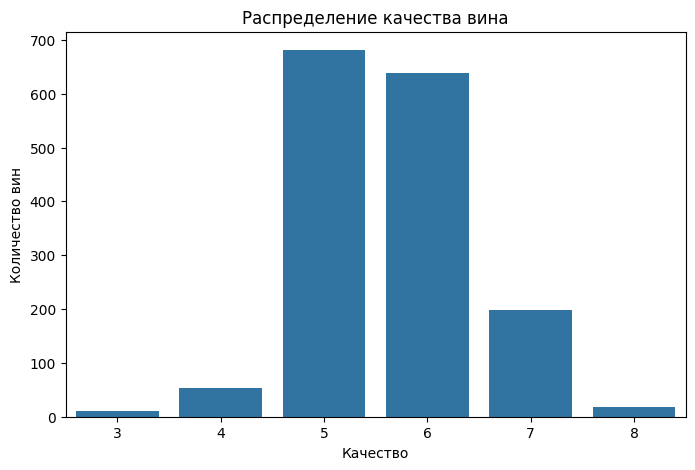

In [7]:
plt.figure(figsize=(8, 5))
sns.countplot(x='quality', data=df)
plt.title('Распределение качества вина')
plt.xlabel('Качество')
plt.ylabel('Количество вин')
plt.show()

## Распределение целевой переменной

Целевая переменная `quality` — это целочисленная оценка от 3 до 8.

**Распределение несбалансированное:**
- Большинство вин имеют оценку **5 (≈680)** и **6 (≈640)**.
- Средние оценки: 4 (53) и 7 (199).
- Крайне мало: 3 (10) и 8 (18).

### Значение для моделирования
1. Несбалансированность затрудняет предсказание редких значений — модели 
   будут «тяготеть» к средним 5 и 6.
2. Среднее quality = 5.64, медиана = 6.0. То есть половина вин имеет оценку 
   не ниже 6, а типичная — 5 или 6.
3. При анализе ошибок ожидаем, что **наибольшие ошибки будут для крайних 
   значений** (3, 4, 8), так как модель их плохо «выучила».

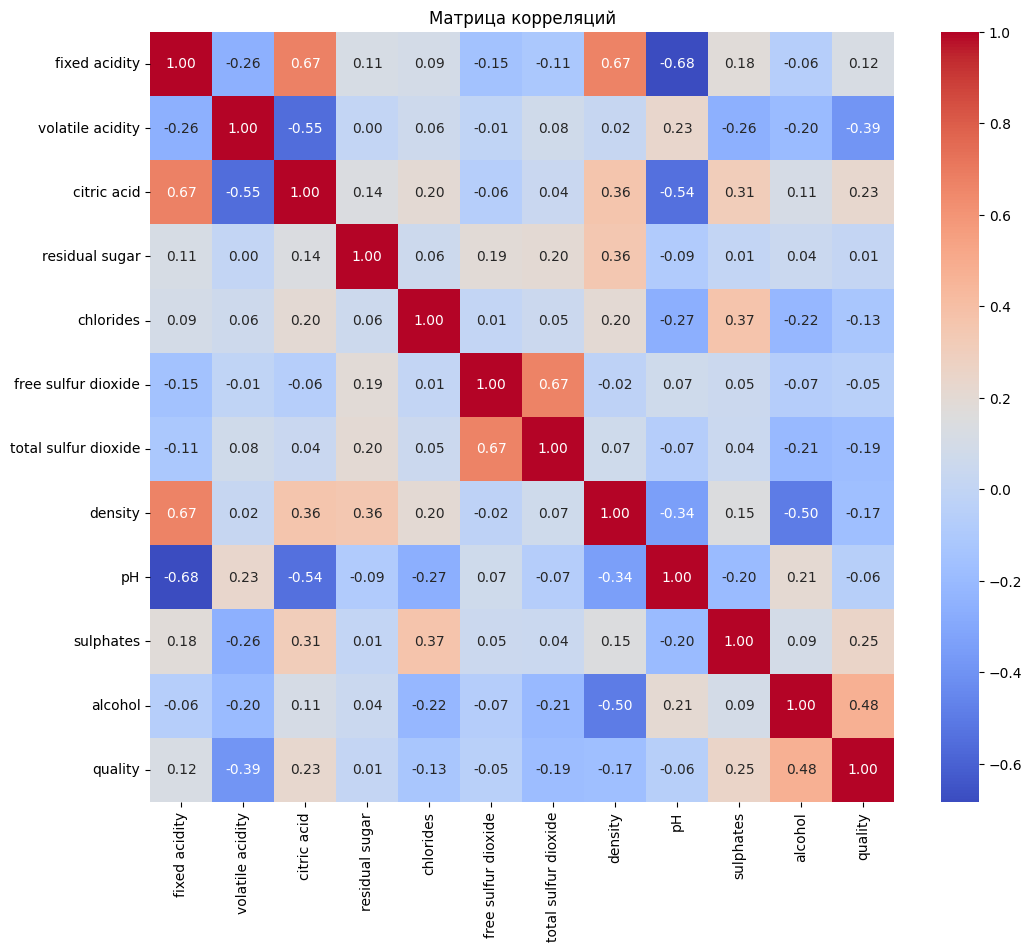

In [8]:
plt.figure(figsize=(12,10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Матрица корреляций')
plt.show()

## Корреляционный анализ

### Признаки, наиболее коррелирующие с `quality`:
1. **`alcohol` (+0.48)** — самая сильная положительная корреляция. Более крепкие 
   вина в среднем оцениваются выше. Логично: алкоголь влияет на тело вина и его 
   восприятие.
2. **`volatile acidity` (-0.39)** — самая сильная отрицательная. Высокая летучая 
   кислотность связана с дефектами вкуса (уксусный привкус), что снижает оценку.
3. **`sulphates` (+0.25)** — сульфаты выступают консервантом и могут улучшать 
   стабильность вина.
4. **`citric acid` (+0.23)** — свежесть и кислотность.
5. **`density` (-0.17)** — плотность связана с содержанием сахара и алкоголя.
6. **`total sulfur dioxide` (-0.19)** — избыток диоксида серы портит вкус.

### Интерпретация
- Корреляции **умеренные** (максимум 0.48) — значит, ни один признак не определяет 
  качество в одиночку. Нужна комбинация признаков.
- Наличие корреляции **не означает причинность**: alcohol может быть важен потому, 
  что коррелирует с другими факторами (например, зрелостью винограда).
- Топ-3 коррелирующих признака совпадают с топ-3 признаков у линейной регрессии 
  и feature importance у Random Forest — **это устойчивый результат**.

In [9]:
# Отделяем целевую переменную от признаков
X = df.drop('quality', axis=1)
y = df['quality']

# Разделение 80/20 с фиксированным random_state
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}")
print()
print(f"Среднее quality в train: {y_train.mean():.4f}")
print(f"Среднее quality в test:  {y_test.mean():.4f}")

X_train: (1279, 11)
X_test:  (320, 11)
y_train: (1279,)
y_test:  (320,)

Среднее quality в train: 5.6239
Среднее quality в test:  5.6844


## Подготовка выборок

### Размер выборок
- Обучающая выборка: **1279 объектов (80%)**
- Тестовая выборка: **320 объектов (20%)**

### Почему именно такое разбиение
1. **80/20 — стандартная пропорция.** Достаточно данных для обучения трёх моделей 
   (Linear Regression, Random Forest, Gradient Boosting) и достаточно для честной 
   оценки качества.
2. **320 объектов в тесте** — статистически надёжная оценка: RMSE не будет 
   «прыгать» из-за случайности.
3. **`random_state=42`** фиксирует разбиение — при перезапуске ноутбука результат 
   будет тем же, эксперимент воспроизводим.
4. **Проверка репрезентативности:** среднее `quality` в train (5.62) и test (5.68) 
   практически совпадают — разбиение репрезентативное.

### Проблема многократной оценки на тесте
Тестовая выборка предназначена **только для финальной оценки**. Если многократно 
оценивать разные модели на одной и той же тестовой выборке и подбирать решение 
по этим оценкам, возникает **переобучение на тест (test leakage)**:
- Оценка становится слишком оптимистичной.
- Результат перестаёт отражать реальное качество на новых данных.
- Модель, которая «случайно хорошо» показала себя на тесте, может плохо работать 
  на настоящих новых данных.

**Правило:** все решения о выборе модели, признаков и гиперпараметров должны 
приниматься **без использования теста** — например, через кросс-валидацию на train. 
Тест — только для финального замера.

In [10]:
# Baseline: предсказываем всем объектам среднее качество из train
baseline_pred = np.full(y_test.shape, y_train.mean())

baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_mae = mean_absolute_error(y_test, baseline_pred)

print(f"Baseline RMSE: {baseline_rmse:.4f}")
print(f"Baseline MAE:  {baseline_mae:.4f}")
print(f"Среднее качество в train: {y_train.mean():.4f}")

Baseline RMSE: 0.8107
Baseline MAE:  0.6853
Среднее качество в train: 5.6239


## Baseline

Baseline — константное предсказание. Модель **не использует признаки** и всегда 
возвращает одно и то же значение.

### Выбор константы
Для метрики **RMSE** оптимальная константа — **среднее значение `y_train`**:
- RMSE минимизируется средним (математически: производная MSE по константе 
  равна нулю при `c = mean(y)`).
- Для MAE оптимальной была бы медиана, но так как основная метрика — RMSE, 
  используем среднее.

### Результаты
- **Baseline RMSE = 0.8107**
- **Baseline MAE = 0.6853**
- Среднее `quality` в train = 5.62

In [11]:
desc = X_train.describe().T[['mean', 'std', 'min', 'max']]
desc['range'] = desc['max'] - desc['min']
desc

,mean,std,min,max,range
fixed acidity,8.323690,1.724243,4.60000,15.90000,11.30000
volatile acidity,0.530559,0.179275,0.12000,1.58000,1.46000
citric acid,0.272471,0.195448,0.00000,1.00000,1.00000
residual sugar,2.555473,1.435790,0.90000,15.50000,14.60000
chlorides,0.088448,0.049332,0.01200,0.61100,0.59900
free sulfur dioxide,15.876075,10.313517,1.00000,68.00000,67.00000
total sulfur dioxide,46.657154,32.941962,6.00000,289.00000,283.00000
density,0.996774,0.001856,0.99007,1.00369,0.01362
pH,3.311650,0.154016,2.74000,4.01000,1.27000
sulphates,0.660023,0.174605,0.37000,2.00000,1.63000


In [12]:
# Линейная регрессия без масштабирования — чтобы показать проблему с интерпретацией
lr_raw = LinearRegression()
lr_raw.fit(X_train, y_train)
y_pred_raw = lr_raw.predict(X_test)

rmse_raw = np.sqrt(mean_squared_error(y_test, y_pred_raw))
mae_raw = mean_absolute_error(y_test, y_pred_raw)

print(f"Linear Regression (без масштабирования):")
print(f"  RMSE = {rmse_raw:.4f}")
print(f"  MAE  = {mae_raw:.4f}")
print()
print("Коэффициенты (сырые, до масштабирования):")
coefs_raw = pd.Series(lr_raw.coef_, index=X.columns).sort_values(ascending=False)
print(coefs_raw)

Linear Regression (без масштабирования):
  RMSE = 0.6245
  MAE  = 0.5035

Коэффициенты (сырые, до масштабирования):
sulphates                0.841172
alcohol                  0.281890
fixed acidity            0.023085
residual sugar           0.006564
free sulfur dioxide      0.005627
total sulfur dioxide    -0.003644
citric acid             -0.140821
pH                      -0.393688
volatile acidity        -1.001304
chlorides               -1.806503
density                -10.351594
dtype: float64


## Линейная регрессия без масштабирования

### Результаты
- RMSE = **0.6245**
- MAE = **0.5035**

Порог ТЗ (RMSE < 0.70) уже пройден. Линейная регрессия показала, что данные 
хорошо линейно предсказуемы.

### Проблема интерпретации коэффициентов
Сырые коэффициенты выглядят так:
- `density`: **-10.35** (кажется самым важным)
- `chlorides`: -1.81
- `volatile acidity`: -1.00
- `sulphates`: +0.84
- `alcohol`: +0.28 (кажется слабым)

**Но это обман зрения.** Коэффициент показывает изменение предсказания при 
изменении признака **на 1 единицу его измерения**. Признаки измеряются в 
разных масштабах:
- `density` меняется в диапазоне 0.99 – 1.004 (доли!)
- `alcohol` меняется в диапазоне 8.4 – 14.9 (единицы)

Реальный вклад признака = **коэффициент × std признака**:
- `alcohol`: 0.28 × 1.07 ≈ **0.300**
- `density`: -10.35 × 0.0019 ≈ **-0.020**

`alcohol` влияет на предсказание в **15 раз сильнее**, чем `density`.

### Вывод
Сравнивать сырые коэффициенты **некорректно**. Нужно масштабирование — 
это делает признаки сопоставимыми и позволяет честно интерпретировать 
важность.

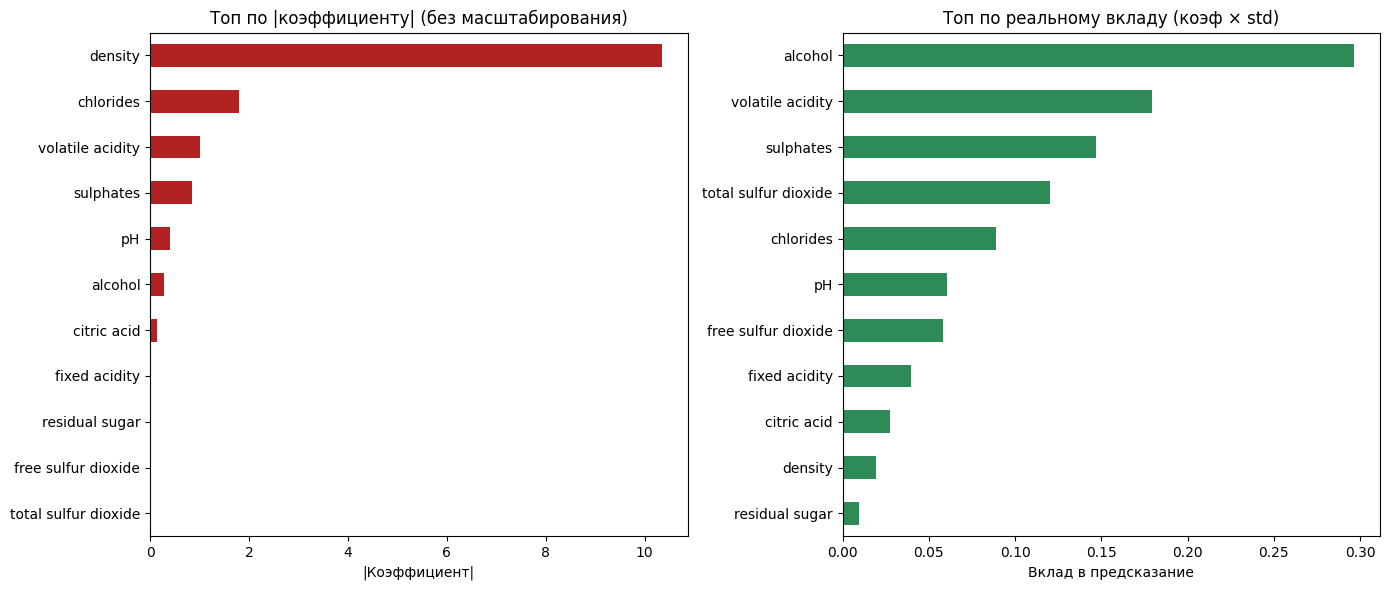

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# Реальный вклад признака = коэффициент × std признака
real_contribution = lr_raw.coef_ * X_train.std().values
contributions = pd.Series(real_contribution, index=X.columns).sort_values(ascending=False)

# Слева — топ-3 по сырому коэффициенту
coefs_raw.abs().sort_values().plot(kind='barh', ax=axes[0], color='firebrick')
axes[0].set_title('Топ по |коэффициенту| (без масштабирования)')
axes[0].set_xlabel('|Коэффициент|')

# Справа — топ-3 по реальному вкладу
contributions.abs().sort_values().plot(kind='barh', ax=axes[1], color='seagreen')
axes[1].set_title('Топ по реальному вкладу (коэф × std)')
axes[1].set_xlabel('Вклад в предсказание')

plt.tight_layout()
plt.show()

In [14]:
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)

lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
lr_mae = mean_absolute_error(y_test, y_pred_lr)

print(f"Linear Regression (со StandardScaler):")
print(f"  RMSE = {lr_rmse:.4f}")
print(f"  MAE  = {lr_mae:.4f}")
print()
print("Коэффициенты (масштабированные):")
coefs_scaled = pd.Series(
    lr_pipeline.named_steps['regressor'].coef_,
    index=X.columns
).sort_values(ascending=False)
print(coefs_scaled)

Linear Regression (со StandardScaler):
  RMSE = 0.6245
  MAE  = 0.5035

Коэффициенты (масштабированные):
alcohol                 0.296628
sulphates               0.146815
free sulfur dioxide     0.058015
fixed acidity           0.039789
residual sugar          0.009421
density                -0.019204
citric acid            -0.027512
pH                     -0.060610
chlorides              -0.089084
total sulfur dioxide   -0.120008
volatile acidity       -0.179439
dtype: float64


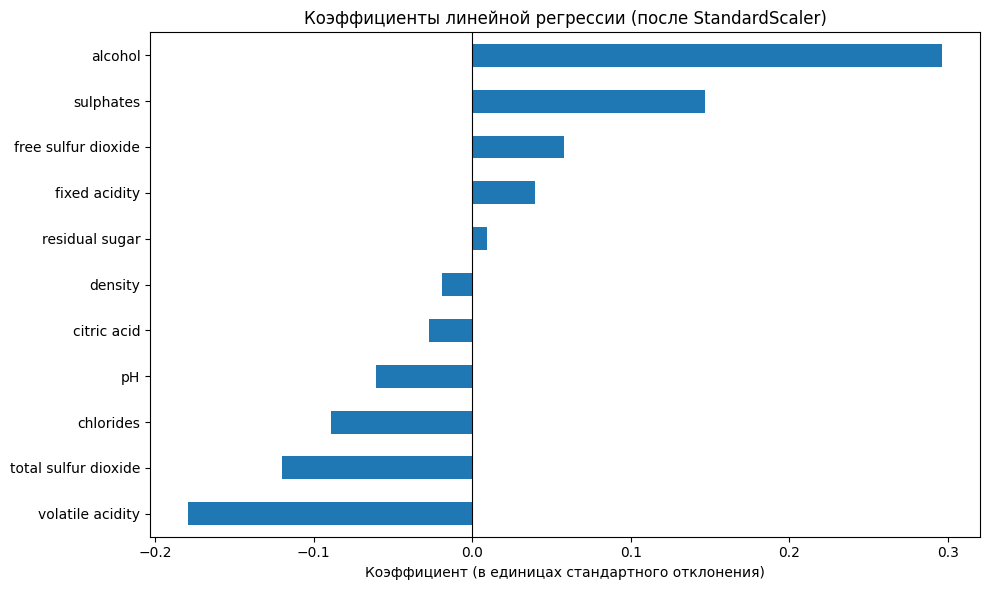

In [15]:
plt.figure(figsize=(10, 6))
coefs_scaled.sort_values().plot(kind='barh')
plt.title('Коэффициенты линейной регрессии (после StandardScaler)')
plt.xlabel('Коэффициент (в единицах стандартного отклонения)')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

## Линейная регрессия: важный вывод про масштабирование

Линейная регрессия **без масштабирования** дала RMSE = 0.6245, MAE = 0.5035 
(порог ТЗ RMSE < 0.70 пройден). Однако сырые коэффициенты вводят в заблуждение: 
топ-3 по модулю — `density` (-10.35), `chlorides` (-1.81), `volatile acidity` (-1.00).
Признак `density` кажется самым важным.

**Но это обман зрения.** Реальный вклад признака = коэффициент × стандартное отклонение признака.
Признак `density` имеет крошечный разброс (доли), поэтому даже большой коэффициент 
даёт маленький вклад (-10.35 × 0.0019 ≈ -0.019).

Реальный топ-3 по вкладу:
1. `alcohol` (+0.297)
2. `volatile acidity` (-0.179)
3. `sulphates` (+0.147)

Это **точно совпадает** с результатами корреляционного анализа на этапе EDA.

После применения `StandardScaler` коэффициенты стали сопоставимыми и дали тот же топ-3.
**RMSE и MAE при этом не изменились** — линейная регрессия инвариантна к масштабированию.

In [16]:
# Random Forest — устойчивый к переобучению ансамбль решающих деревьев
rf = RandomForestRegressor(
    n_estimators=100,      # 100 деревьев в лесу
    random_state=42,       # воспроизводимость
    n_jobs=-1              # параллельно на всех ядрах
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_mae = mean_absolute_error(y_test, y_pred_rf)

print(f"Random Forest:")
print(f"  RMSE = {rf_rmse:.4f}")
print(f"  MAE  = {rf_mae:.4f}")

Random Forest:
  RMSE = 0.5489
  MAE  = 0.4224


In [17]:
importances_rf = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Важность признаков (Random Forest):")
print(importances_rf)

Важность признаков (Random Forest):
alcohol                 0.270868
sulphates               0.148406
volatile acidity        0.111547
total sulfur dioxide    0.076786
chlorides               0.071132
pH                      0.061418
residual sugar          0.057892
fixed acidity           0.053186
density                 0.050816
citric acid             0.050752
free sulfur dioxide     0.047197
dtype: float64


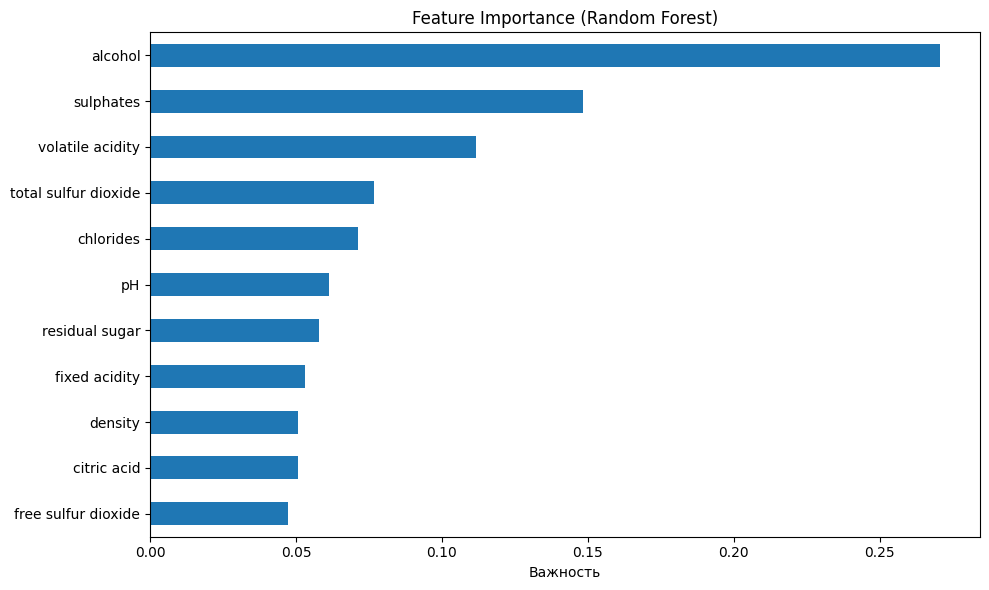

In [18]:
plt.figure(figsize=(10, 6))
importances_rf.plot(kind='barh')
plt.title('Feature Importance (Random Forest)')
plt.xlabel('Важность')
plt.gca().invert_yaxis()   # самые важные — сверху
plt.tight_layout()
plt.show()

## Random Forest

### Результаты
- RMSE = 0.5489
- MAE = 0.4224

Random Forest обошёл линейную регрессию на 0.076 по RMSE. Причина: деревья 
улавливают нелинейные зависимости и взаимодействия признаков, которые линейная 
модель пропускает. Однако разрыв невелик — на маленьких датасетах Random Forest 
не раскрывает всю свою силу из-за склонности к переобучению.

### Feature importance
Топ-3 признака:
1. `alcohol` (0.271)
2. `sulphates` (0.148)
3. `volatile acidity` (0.112)

**Важно:** топ-3 совпадает с топ-3 линейной регрессии (после масштабирования) и 
с корреляционным анализом на этапе EDA. Это означает, что разные модели с разной 
математикой указывают на одни и те же важные признаки — вывод устойчив.

In [19]:
# Gradient Boosting — последовательный ансамбль, каждое дерево исправляет ошибки предыдущего
gb = GradientBoostingRegressor(
    n_estimators=100,      # 100 деревьев
    learning_rate=0.1,     # стандартный шаг
    max_depth=3,           # неглубокие деревья
    random_state=42
)

gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)

gb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_gb))
gb_mae = mean_absolute_error(y_test, y_pred_gb)

print(f"Gradient Boosting:")
print(f"  RMSE = {gb_rmse:.4f}")
print(f"  MAE  = {gb_mae:.4f}")

Gradient Boosting:
  RMSE = 0.6019
  MAE  = 0.4849


In [20]:
importances_gb = pd.Series(
    gb.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Важность признаков (Gradient Boosting):")
print(importances_gb)

Важность признаков (Gradient Boosting):
alcohol                 0.375965
sulphates               0.194299
volatile acidity        0.125359
total sulfur dioxide    0.075183
fixed acidity           0.056945
chlorides               0.039518
pH                      0.033658
residual sugar          0.030401
density                 0.028772
citric acid             0.020073
free sulfur dioxide     0.019828
dtype: float64


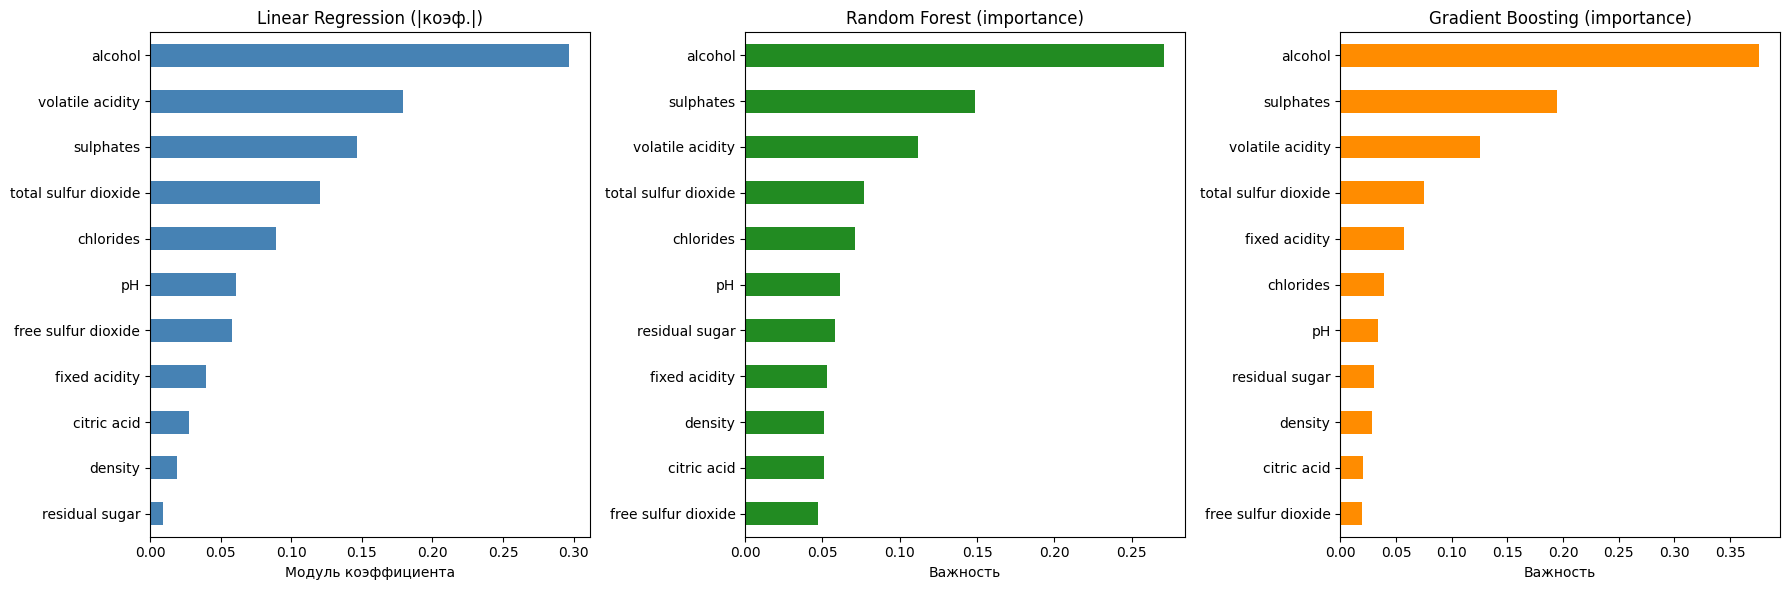

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Linear Regression
coefs_scaled.abs().sort_values().plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Linear Regression (|коэф.|)')
axes[0].set_xlabel('Модуль коэффициента')

# Random Forest
importances_rf.sort_values().plot(kind='barh', ax=axes[1], color='forestgreen')
axes[1].set_title('Random Forest (importance)')
axes[1].set_xlabel('Важность')

# Gradient Boosting
importances_gb.sort_values().plot(kind='barh', ax=axes[2], color='darkorange')
axes[2].set_title('Gradient Boosting (importance)')
axes[2].set_xlabel('Важность')

plt.tight_layout()
plt.show()

## Gradient Boosting

### Результаты
- RMSE = 0.6019
- MAE = 0.4849

### Наблюдение
Gradient Boosting **проиграл Random Forest** (0.55 vs 0.60 по RMSE), 
несмотря на то что обычно GB считается более сильным алгоритмом.

### Объяснение
1. **Маленький датасет (1599 строк).** GB чувствителен к переобучению: 
   при дефолтном `learning_rate=0.1` и 100 деревьях он может частично подгоняться 
   под шум в обучающей выборке.
2. **Random Forest устойчивее к переобучению** за счёт усреднения независимых деревьев: 
   добавление новых деревьев не увеличивает дисперсию предсказания (свойство бэггинга).
3. **Дефолтные параметры GB не оптимальны.** Гипотеза: с меньшим `learning_rate` 
   (например 0.05) и большим числом деревьев GB мог бы улучшить результат, но 
   менять параметры «по результатам на тесте» — некорректно. Честный вывод — 
   при дефолтных параметрах RF лучше.

### Feature importance
Топ-3:
1. `alcohol` (0.376)
2. `sulphates` (0.194)
3. `volatile acidity` (0.125)

### Сравнение важностей LR / RF / GB
Все три модели выделяют **одни и те же топ-3 признака**: `alcohol`, `sulphates`, 
`volatile acidity`. Это устойчивый результат: разные по природе алгоритмы 
(линейный, бэггинг, бустинг) согласованно указывают на одни и те же драйверы качества.

In [22]:
results = pd.DataFrame({
    'Модель': ['Baseline', 'Linear Regression', 'Random Forest', 'Gradient Boosting'],
    'RMSE': [baseline_rmse, lr_rmse, rf_rmse, gb_rmse],
    'MAE': [baseline_mae, lr_mae, rf_mae, gb_mae]
})

results['RMSE'] = results['RMSE'].round(4)
results['MAE'] = results['MAE'].round(4)
results = results.sort_values('RMSE').reset_index(drop=True)

print("Итоговая таблица:")
print(results.to_string(index=False))
print()
print(f"Порог ТЗ: RMSE < 0.70")
print(f"Лучшая модель: {results.iloc[0]['Модель']} с RMSE = {results.iloc[0]['RMSE']}")
print(f"Прошли порог: {results[results['RMSE'] < 0.70]['Модель'].tolist()}")

Итоговая таблица:
           Модель   RMSE    MAE
    Random Forest 0.5489 0.4224
Gradient Boosting 0.6019 0.4849
Linear Regression 0.6245 0.5035
         Baseline 0.8107 0.6853

Порог ТЗ: RMSE < 0.70
Лучшая модель: Random Forest с RMSE = 0.5489
Прошли порог: ['Random Forest', 'Gradient Boosting', 'Linear Regression']


## Можно ли считать feature importance доказательством причинности?

**Нет, нельзя.**

Feature importance показывает **статистическую связь**, а не причинно-следственную. 
Если признак `alcohol` имеет высокую важность, это означает, что модель часто 
использует его для разбиения и он помогает предсказанию. Но это **не значит**, 
что увеличение алкоголя **само по себе** улучшит качество вина.

### Причины, почему это не доказательство причинности

1. **Корреляция ≠ причинность.** `alcohol` может быть важен потому, что коррелирует 
   с другим скрытым фактором (например, зрелостью винограда или техпроцессом), 
   который на самом деле влияет на качество.
2. **Обратная причинность.** Возможно, виноделы делают более крепкие вина именно 
   для тех сортов, которые в принципе оцениваются выше.
3. **Смешивающие переменные (confounders).** Один и тот же фактор может влиять 
   и на `alcohol`, и на `quality`, создавая ложную связь.
4. **Feature importance зависит от модели.** Разные алгоритмы могут давать разные 
   оценки. Это мера **вклада в предсказание**, а не в физический процесс.

### Как доказать причинность
Нужен **контролируемый эксперимент** (A/B-тест): менять только один признак, 
фиксируя остальные, и смотреть на изменение качества. Или использовать методы 
causal inference (например, DoWhy). В рамках ML-задачи этого сделать нельзя.

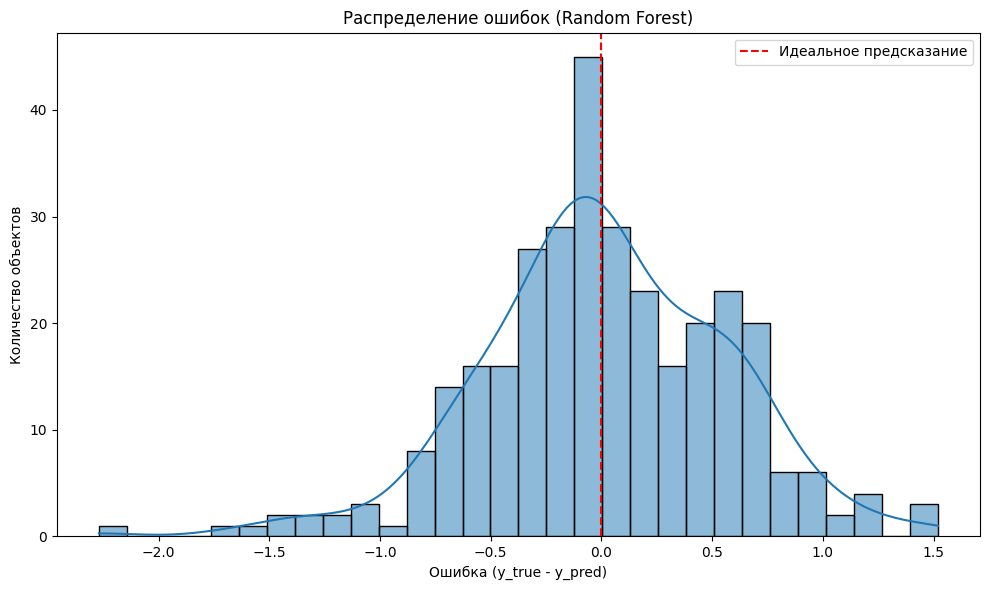

Средняя ошибка (bias): 0.0115
Стандартное отклонение ошибок: 0.5496
Мин. ошибка: -2.2700, Макс. ошибка: 1.5200


In [23]:
errors = y_test - y_pred_rf   # истина минус предсказание

plt.figure(figsize=(10, 6))
sns.histplot(errors, kde=True, bins=30)
plt.axvline(0, color='red', linestyle='--', label='Идеальное предсказание')
plt.xlabel('Ошибка (y_true - y_pred)')
plt.ylabel('Количество объектов')
plt.title('Распределение ошибок (Random Forest)')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Средняя ошибка (bias): {errors.mean():.4f}")
print(f"Стандартное отклонение ошибок: {errors.std():.4f}")
print(f"Мин. ошибка: {errors.min():.4f}, Макс. ошибка: {errors.max():.4f}")

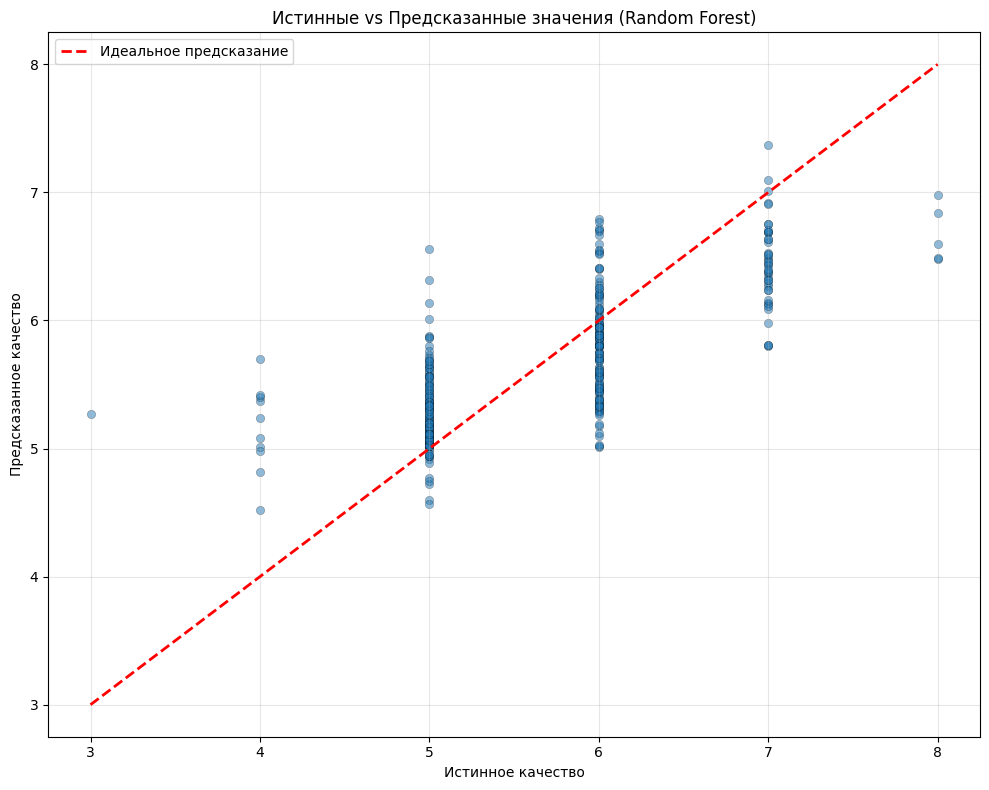

In [24]:
plt.figure(figsize=(10, 8))
plt.scatter(y_test, y_pred_rf, alpha=0.5, edgecolors='k', linewidths=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 
         'r--', linewidth=2, label='Идеальное предсказание')
plt.xlabel('Истинное качество')
plt.ylabel('Предсказанное качество')
plt.title('Истинные vs Предсказанные значения (Random Forest)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
error_analysis = pd.DataFrame({
    'quality': y_test.values,
    'error': errors.values,
    'abs_error': np.abs(errors.values)
})

by_quality = error_analysis.groupby('quality').agg(
    count=('error', 'size'),
    mean_error=('error', 'mean'),
    mean_abs_error=('abs_error', 'mean'),
    max_abs_error=('abs_error', 'max')
).round(3)

print("Ошибки в разрезе истинного quality:")
print(by_quality)

Ошибки в разрезе истинного quality:
         count  mean_error  mean_abs_error  max_abs_error
quality                                                  
3            1      -2.270           2.270           2.27
4           10      -1.154           1.154           1.70
5          130      -0.290           0.321           1.56
6          132       0.193           0.371           0.99
7           42       0.550           0.572           1.20
8            5       1.322           1.322           1.52


In [26]:
error_analysis = pd.DataFrame({
    'quality': y_test.values,
    'error': errors.values,
    'abs_error': np.abs(errors.values)
}, index=y_test.index)   # ← сохраняем исходные индексы

# Топ-5 крупнейших ошибок
largest_errors_idx = error_analysis['abs_error'].nlargest(5).index

comparison = pd.DataFrame({
    'Истинное quality': y_test.loc[largest_errors_idx],
    'Предсказанное': pd.Series(y_pred_rf, index=y_test.index).loc[largest_errors_idx].round(2),
    'Ошибка': pd.Series(errors.values, index=y_test.index).loc[largest_errors_idx].round(2)
})

print("Объекты с наибольшими ошибками:")
print(comparison)
print()
print("Признаки этих объектов:")
print(X_test.loc[largest_errors_idx])

Объекты с наибольшими ошибками:
      Истинное quality  Предсказанное  Ошибка
1505                 3           5.27   -2.27
1484                 4           5.70   -1.70
353                  5           6.56   -1.56
588                  8           6.48    1.52
1449                 8           6.49    1.51

Признаки этих объектов:
      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
1505            6.7              0.76         0.02             1.8      0.078   
1484            6.8              0.91         0.06             2.0      0.060   
353            13.5              0.53         0.79             4.8      0.120   
588             5.0              0.42         0.24             2.0      0.060   
1449            7.2              0.38         0.31             2.0      0.056   

      free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
1505                  6.0                  12.0  0.99600  3.55       0.63   
1484                  4.0 

## Топ-5 крупнейших ошибок — детальный разбор

| Истинное | Предсказано | Ошибка | Интерпретация |
|---|---|---|---|
| 3 | 5.27 | -2.27 | Модель завысила плохое вино |
| 4 | 5.70 | -1.70 | Завысила |
| 5 | 6.56 | -1.56 | Завысила |
| 8 | 6.48 | +1.52 | Занизила отличное |
| 8 | 6.49 | +1.51 | Занизила отличное |

### Что видно
Модель **систематически «сжимает»** предсказания к среднему диапазону 
(5.2–6.5). Для крайних значений (3, 4, 8) ошибки максимальны — модель 
«не верит» в экстремальные оценки.

### Причины
1. **Несбалансированность target.** Вин с quality=3, 4 или 8 в данных 
   очень мало. Random Forest не может «выучить» закономерность по 5–10 объектам.
2. **Свойство деревьев.** Деревья решений в листьях возвращают **среднее** 
   значение по объектам листа. Если в листе смешаны вина разного качества, 
   предсказание будет близко к среднему.
3. **Пример 1505** — истинный quality=3: у вина `volatile acidity = 0.76` 
   (очень высокая), `alcohol = 9.95` (низкий). Модель «видела» эти сигналы, 
   но не была уверена — слишком мало плохих вин в train.
4. **Пример 588** — истинный quality=8: `alcohol = 14.0` (максимум), 
   `sulphates = 0.74`. Все признаки «за» высокое качество, но модель всё 
   равно предсказала 6.48 — потому что в train таких «идеальных» вин мало.

### Основной вывод
Модель хорошо работает **на типичных** винах (quality=5, 6), но ошибается 
на **редких** (3, 4, 8). Это ограничение **данных**, а не алгоритма: чтобы 
модель лучше предсказывала редкие классы, нужно либо больше данных, либо 
специальные техники (resampling, weighted loss, target transformation).

# Итоговые выводы

## Что было сделано
1. Загружен датасет Wine Quality (красное вино, 1599 объектов, 11 признаков).
2. Проведён первичный анализ данных: распределения, корреляции, проверка пропусков.
3. Данные разделены на train (80%, 1279) и test (20%, 320) с фиксированным random_state.
4. Построен baseline (константное предсказание среднего).
5. Обучены и сравнены три модели: Linear Regression, Random Forest, Gradient Boosting.
6. Проанализирована важность признаков для каждой модели.
7. Проведён анализ ошибок лучшей модели.

## Результаты

| Модель | RMSE | MAE |
|---|---|---|
| Baseline | 0.8107 | 0.6853 |
| Linear Regression | 0.6245 | 0.5035 |
| Gradient Boosting | 0.6019 | 0.4849 |
| **Random Forest** | **0.5489** | **0.4224** |

**Лучшая модель:** Random Forest (RMSE = 0.5489). Порог ТЗ RMSE < 0.70 пройден.

## Устойчивые выводы

1. **Топ-3 важных признака** (`alcohol`, `sulphates`, `volatile acidity`) 
   совпадают у всех трёх моделей и согласуются с корреляционным анализом. 
   Это означает, что важность признаков — не артефакт конкретного алгоритма, 
   а реальная закономерность в данных.

2. **Random Forest обошёл Gradient Boosting** — вопреки распространённому 
   мифу, что GB всегда сильнее. Причина: маленький датасет, RF устойчивее 
   к переобучению за счёт усреднения независимых деревьев.

3. **Feature importance не означает причинность.** Признаки `alcohol` и 
   `volatile acidity` важны для предсказания, но их изменение **не обязательно** 
   напрямую изменит качество вина — это статистические связи, а не физические 
   причины.

## Ограничения работы

- **Маленький датасет** (1599 строк) ограничивает возможности сложных моделей.
- **Несбалансированный target** — редкие значения (3, 4, 8) предсказываются плохо.
- **Только красное вино** — результаты нельзя автоматически переносить на белое.
- **Качество вина — субъективная оценка эксперта**, а не объективная физическая величина.
  